In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

In [ ]:
image = cv2.imread("practice 2/img.jpg")
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

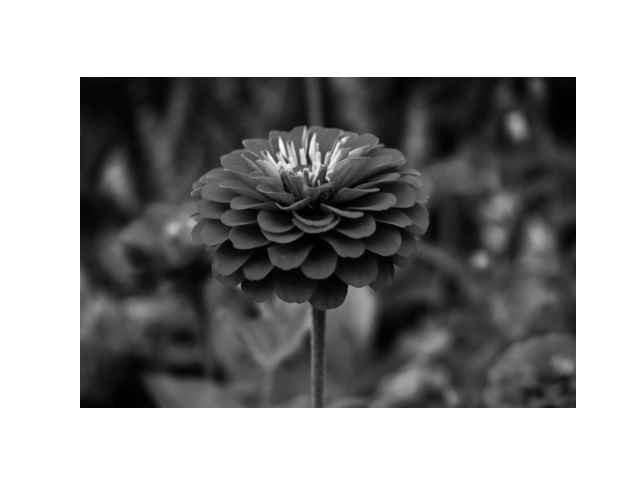
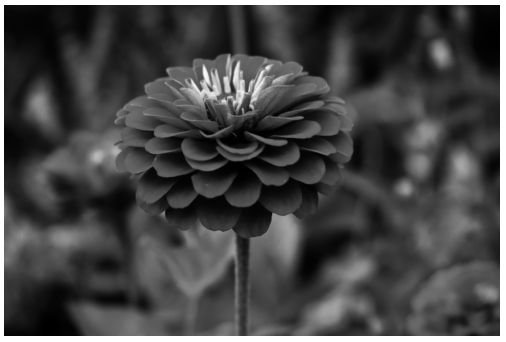

1.Зашумить изображение при помощи шума гаусса, постоянного шума.

In [ ]:
#Гаус
mean = 0
stddev = 200
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)
image_gauss = cv2.add(image_gray,noise_gauss)
plt.imshow(image_gauss, cmap="gray")

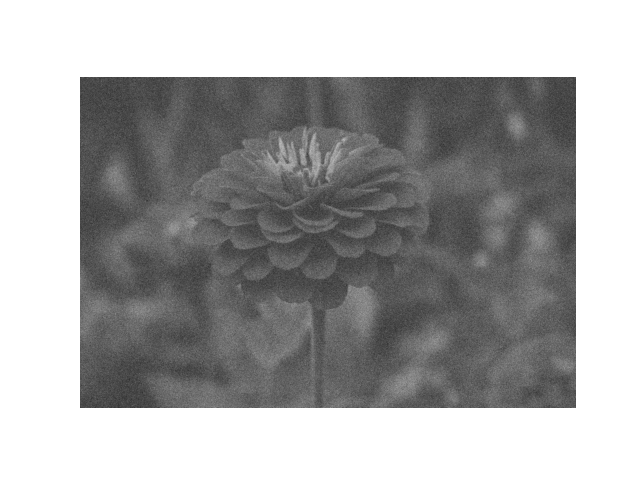

In [ ]:
#Постоянный
np.random.seed(100)
a, b = 25, 125
noise_constant = np.random.uniform(a, b, image_gray.shape).astype(np.uint8)
image_noise_constant = cv2.add(image_gray, noise_constant)
plt.imshow(image_noise_constant, cmap='gray')

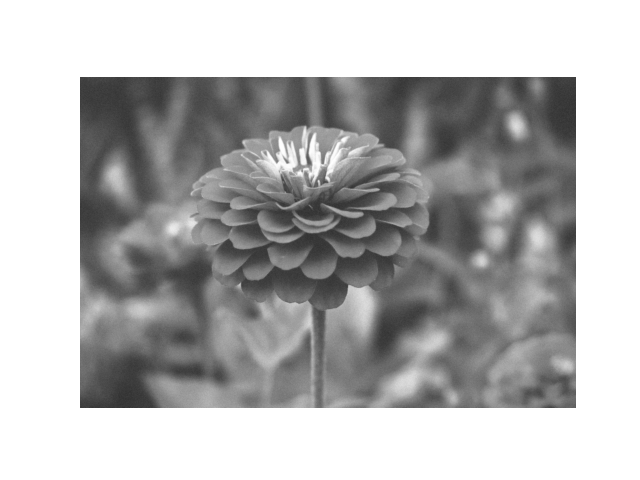

2.Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.

In [ ]:
# 1. Медианный фильтр
image_gauss_median = cv2.medianBlur(image_gauss, 5)
image_constant_median = cv2.medianBlur(image_noise_constant, 5)
# 2. Фильтр Гаусса
image_gauss_gaussian = cv2.GaussianBlur(image_gauss, (5, 5), 0)
image_constant_gaussian = cv2.GaussianBlur(image_noise_constant, (5, 5), 0)
# 3. Билатеральный фильтр
image_gauss_bilateral = cv2.bilateralFilter(image_gauss, 9, 75, 75)
image_constant_bilateral = cv2.bilateralFilter(image_noise_constant, 9, 75, 75)
# 4. Фильтр нелокальных средних
image_gauss_nlm = cv2.fastNlMeansDenoising(image_gauss, None, 20, 7, 21)
image_constant_nlm = cv2.fastNlMeansDenoising(image_noise_constant, None, 20, 7, 21)

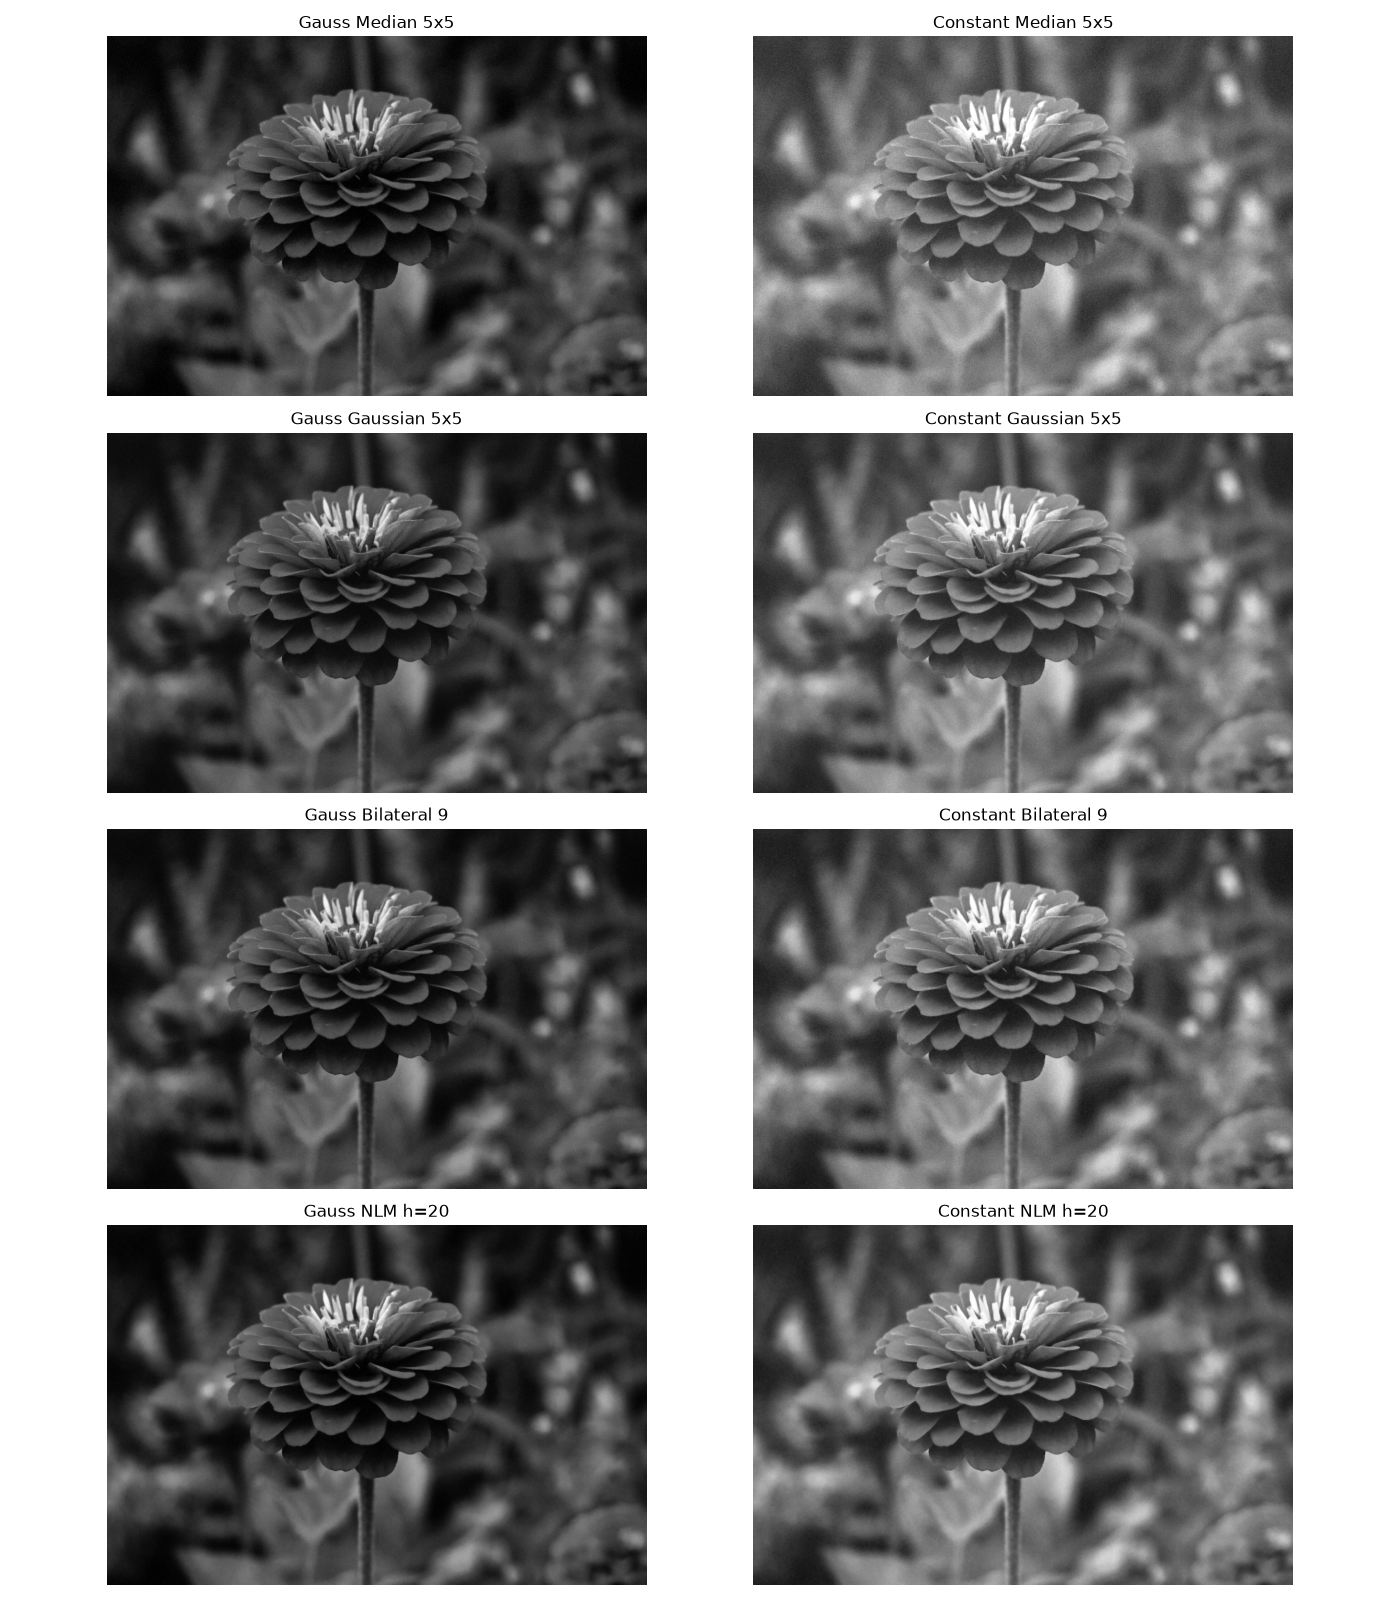

In [ ]:
plt.figure(figsize=(16, 16))

plt.subplot(4, 2, 1);plt.imshow(image_gauss_median, cmap='gray');plt.title("Gauss Median 5x5");plt.axis('off')

plt.subplot(4, 2, 2);plt.imshow(image_constant_median, cmap='gray');plt.title("Constant Median 5x5");plt.axis('off')

plt.subplot(4, 2, 3);plt.imshow(image_gauss_gaussian, cmap='gray');plt.title("Gauss Gaussian 5x5");plt.axis('off')

plt.subplot(4, 2, 4);plt.imshow(image_constant_gaussian, cmap='gray');plt.title("Constant Gaussian 5x5");plt.axis('off')

plt.subplot(4, 2, 5);plt.imshow(image_gauss_bilateral, cmap='gray');plt.title("Gauss Bilateral 9");plt.axis('off')

plt.subplot(4, 2, 6);plt.imshow(image_constant_bilateral, cmap='gray');plt.title("Constant Bilateral 9");plt.axis('off')

plt.subplot(4, 2, 7);plt.imshow(image_gauss_nlm, cmap='gray');plt.title("Gauss NLM h=20");plt.axis('off')

plt.subplot(4, 2, 8);plt.imshow(image_constant_nlm, cmap='gray');plt.title("Constant NLM h=20");plt.axis('off')

3.Выяснить, какой фильтр показал лучший результат фильтрации шума.

In [ ]:
gauss = [
    ('Median', image_gauss_median),
    ('Gauss', image_gauss_gaussian),
    ('Bilateral', image_gauss_bilateral),
    ('NLM', image_gauss_nlm)
]

constant = [
    ('Median', image_constant_median),
    ('Gauss', image_constant_gaussian),
    ('Bilateral', image_constant_bilateral),
    ('NLM', image_constant_nlm)
]

for name, img in gauss:
    print('Gauss', name,
          'SSIM:', structural_similarity(image_gray, img),
          'MSE:', mean_squared_error(image_gray, img))

for name, img in constant:
    print('Constant', name,
          'SSIM:', structural_similarity(image_gray, img),
          'MSE:', mean_squared_error(image_gray, img))

Gauss Median SSIM: 0.618986409422264 MSE: 50.102648916666666
Gauss Gauss SSIM: 0.6180711200403188 MSE: 53.77392175
Gauss Bilateral SSIM: 0.7484058301613306 MSE: 30.768348666666668
Gauss NLM SSIM: 0.7985100707262798 MSE: 22.469867791666665

Best Gauss:Gauss NLM SSIM: 0.7985100707262798 MSE: 22.469867791666665

Constant Median SSIM: 0.2964332873696951 MSE: 5643.188535875
Constant Gauss SSIM: 0.3538317357810167 MSE: 5602.0193875
Constant Bilateral SSIM: 0.4200205785697449 MSE: 5577.006884958333
Constant NLM SSIM: 0.4034146871279211 MSE: 5577.173422166667

Best Constant:Constant Bilateral SSIM: 0.4200205785697449 MSE: 5577.006884958333